THIS IS THE SECOND MODEL I MAKE I WILL USE WSL AGAIN AS IT HOLDS ALL MY NATIVE LIBRARIES 


5. HDFC Bank Ltd. aims to improve its loan processing efficiency by predicting whether a loan application should be approved or rejected based on applicant details. Using a dataset containing information such as applicant income, loan amount, credit history, employment status, property area, and other financial indicators, develop a supervised machine learning classification model to categorize applications as Approved or Rejected.

Dataset Size: 4,269 loan applications and 12 columns (~400.3 KB in memory) after dropping loan_id early, because a unique ID holds no learnable pattern.   Feature Breakdown (11 Input Features + 1 Target):9 Numerical (int64) columns: no_of_dependents, income_annum, loan_amount, loan_term, cibil_score, residential_assets_value, commercial_assets_value, luxury_assets_value, and bank_asset_value.   3 Categorical (str) columns: education (Graduate / Not Graduate), self_employed (Yes / No), and the target loan_status (Approved / Rejected).    

 Step 0: Import Libraries
Getting the basic libraries ready for data handling and plotting.

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Set a clean style for the graphs

sns.set_style("whitegrid")
%matplotlib inline

 Step 1: Load and Inspect the Dataq 
 this brings in the dataset and checks out the columns and data types also need to drop the Loan ID column early on because it is just a unique identifier and carries no actual pattern for the model to learn. 
 

In [26]:
# Loads the data

loan_data = pd.read_csv("loan_approval_dataset.csv")

if "loan_id" in loan_data.columns:
    loan_data = loan_data.drop(columns=["loan_id"])
elif "Loan_ID" in loan_data.columns:
    loan_data = loan_data.drop(columns=["Loan_ID"])


print("Dataset Shape:", loan_data.shape)
loan_data.info()

Dataset Shape: (4269, 12)
<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0    no_of_dependents          4269 non-null   int64
 1    education                 4269 non-null   str  
 2    self_employed             4269 non-null   str  
 3    income_annum              4269 non-null   int64
 4    loan_amount               4269 non-null   int64
 5    loan_term                 4269 non-null   int64
 6    cibil_score               4269 non-null   int64
 7    residential_assets_value  4269 non-null   int64
 8    commercial_assets_value   4269 non-null   int64
 9    luxury_assets_value       4269 non-null   int64
 10   bank_asset_value          4269 non-null   int64
 11   loan_status               4269 non-null   str  
dtypes: int64(9), str(3)
memory usage: 400.3 KB


 Step 2: Dealing with Missing Values
Machine learning algorithms throw errors if they hit empty cells. i will need to fill them in logically:
* Numerical columns (like income, loan amount): i will fill these with the median The median is much better than the mean here because it doesn't get pulled too much by extreme outliers (like a few massive incomes)
* Categorical columns (like credit history, gender): i will fill these with the mode which is just the most frequent category.

In [27]:
print("Missing values before cleaning:")
print(loan_data.isnull().sum())


# Fill missing numerical values with median

numerical_cols = loan_data.select_dtypes(include=[np.number]).columns
for col in numerical_cols:
    loan_data[col] = loan_data[col].fillna(loan_data[col].median())

# Fill missing categorical values with the mode

categorical_cols = loan_data.select_dtypes(include=["object"]).columns
for col in categorical_cols:
    loan_data[col] = loan_data[col].fillna(loan_data[col].mode()[0])



print("\nMissing values after cleaning:")
print(loan_data.isnull().sum())

Missing values before cleaning:
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64

Missing values after cleaning:
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64


/tmp/ipykernel_1298/1003588152.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = loan_data.select_dtypes(include=["object"]).columns


Step 3: Exploratory Data Analysis (EDA)
 looks at the data visually to understand the distributions.

Target Variable Distribution
We need to check the balance of our target variable (Loan Status). If it is heavily imbalanced (e.g. 90% approved, 10% rejected), the model will just blindly guess "approved" every time.

['no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'loan_status']


/tmp/ipykernel_1298/332149560.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=target_col, data=loan_data, palette="Set2")


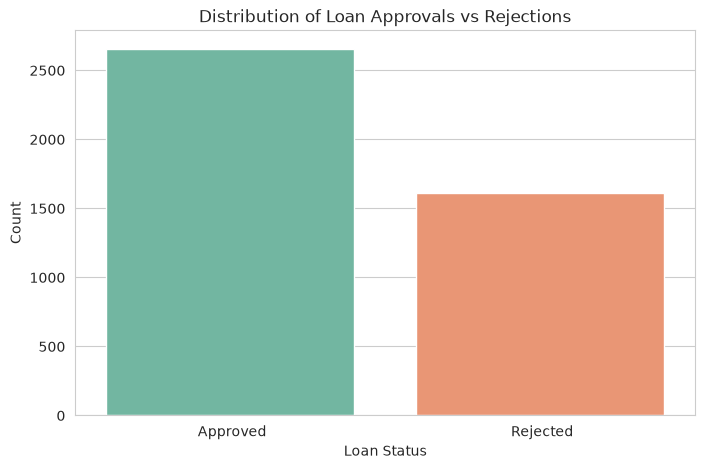

In [28]:
plt.figure(figsize=(8, 5))

# Strip any hidden whitespace from column headers just in case
loan_data.columns = loan_data.columns.str.strip()
print(loan_data.columns.tolist())

target_col = 'loan_status' if 'loan_status' in loan_data.columns else 'Loan_Status'

sns.countplot(x=target_col, data=loan_data, palette="Set2")
plt.title("Distribution of Loan Approvals vs Rejections")
plt.xlabel("Loan Status")
plt.ylabel("Count")
plt.show()


 Applicant Income Histogram
see how applicant incomes are spread out.

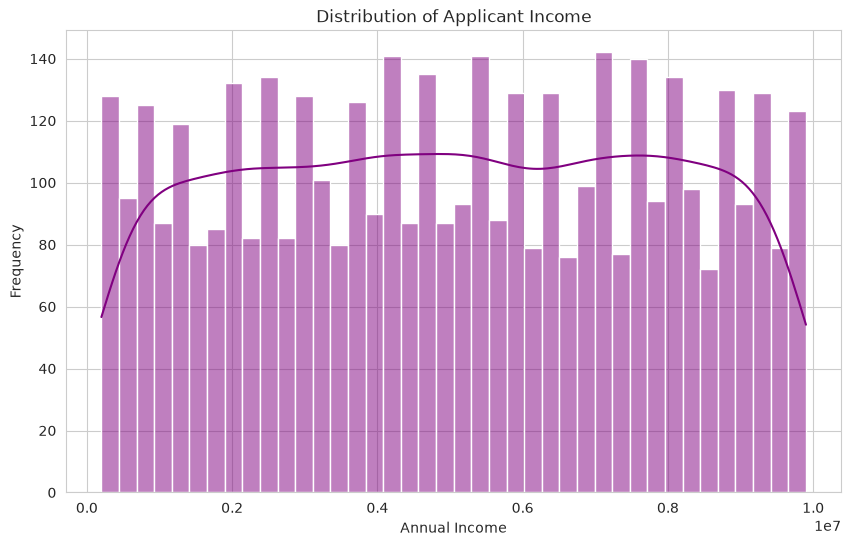

In [29]:
plt.figure(figsize=(10, 6))

sns.histplot(loan_data['income_annum'], bins=40, kde=True, color="purple")

plt.title("Distribution of Applicant Income")
plt.xlabel("Annual Income")
plt.ylabel("Frequency")
plt.show()



Income vs. Loan Amount Scatter

Plotting these two numerical features against each other to see if people with higher incomes generally ask for higher loan amounts and coloring the points by whether they got approved.

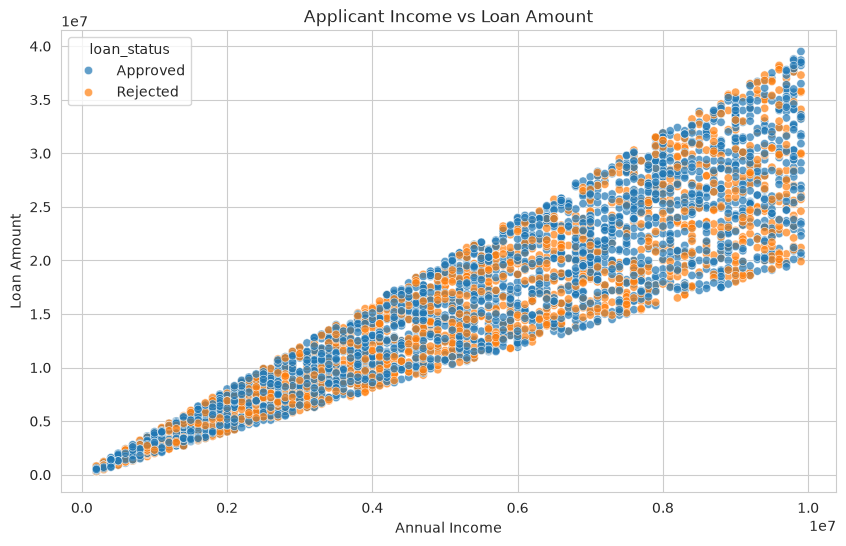

In [30]:
plt.figure(figsize=(10, 6))

sns.scatterplot(x='income_annum', y='loan_amount', hue='loan_status', data=loan_data, alpha=0.7)

plt.title("Applicant Income vs Loan Amount")
plt.xlabel("Annual Income")
plt.ylabel("Loan Amount")
plt.show()


# this should conclude the library imports and initial data exploration so i know what i have to work with adn what do i 

# i am gonna next try to do 


Phase 2: Model Training & Evaluation

separating features and the target label, then splitting 80/20.

for the scaling part, we use StandardScaler note: we gottA to .fit() the scaler on the training data ONLY. if we fit it on the whole dataset before splitting, the scaler learns the mean and variance of the test set. this causes "data leakage" where info from the test set leaks into the training phase making the model  an unfair advantage and a fake high accuracy score. we just 
.transform() the test set separately. so yeah this much should be enough 


In [31]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Strip hidden spaces and convert text categories to 0s and 1s
loan_data['education'] = loan_data['education'].str.strip().replace({'Graduate': 1, 'Not Graduate': 0})
loan_data['self_employed'] = loan_data['self_employed'].str.strip().replace({'Yes': 1, 'No': 0})
loan_data['loan_status'] = loan_data['loan_status'].str.strip().replace({'Approved': 1, 'Rejected': 0})

# 2. Separate features and target
model_features = loan_data.drop(columns=['loan_status'])
target_label = loan_data['loan_status']

# 3. 80/20 split
train_feats, test_feats, train_labels, test_labels = train_test_split(
    model_features, target_label, test_size=0.2, random_state=73
)

# 4. Scale to prevent data leakage
scaler = StandardScaler()
train_feats_scaled = scaler.fit_transform(train_feats)
test_feats_scaled = scaler.transform(test_feats)

training a basic logistic regression as our baseline model, and a random forest to see if an ensemble method does better.


In [32]:

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# Force the labels to be integers to prevent the "unknown label type" crash
train_labels = train_labels.astype('int')
test_labels = test_labels.astype('int')

# Baseline Model
base_log_reg = LogisticRegression(random_state=73)
base_log_reg.fit(train_feats_scaled, train_labels)

# Random Forest
rf_tree_classifier = RandomForestClassifier(n_estimators=100, random_state=73)
rf_tree_classifier.fit(train_feats_scaled, train_labels)


,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",73
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

let's see how it did on the unseen test data     

In [33]:
log_preds = base_log_reg.predict(test_feats_scaled)
rf_preds = rf_tree_classifier.predict(test_feats_scaled)


print("Baseline Logistic Regression Accuracy:", accuracy_score(test_labels, log_preds))
print("Random Forest Accuracy:", accuracy_score(test_labels, rf_preds))




Baseline Logistic Regression Accuracy: 0.9110070257611241
Random Forest Accuracy: 0.9882903981264637


the random forest did way betterthan what i had orignally thought  plotting its confusion matrix to see exactly where it misclassified (false approvals vs false rejections).

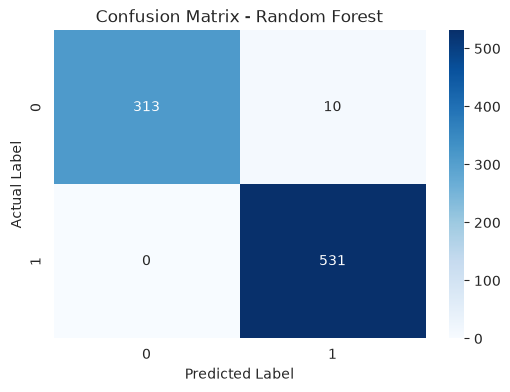

In [34]:
rf_matrix = confusion_matrix(test_labels, rf_preds)


plt.figure(figsize=(6, 4))

sns.heatmap(rf_matrix, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()




pulling the top 5 features from the random forest to see what exactly drives the approval decision behind the scenes.

i haveto do this for pretty much as a  curtsy although i never go the poi nt why other people making these models do stuff lik this 


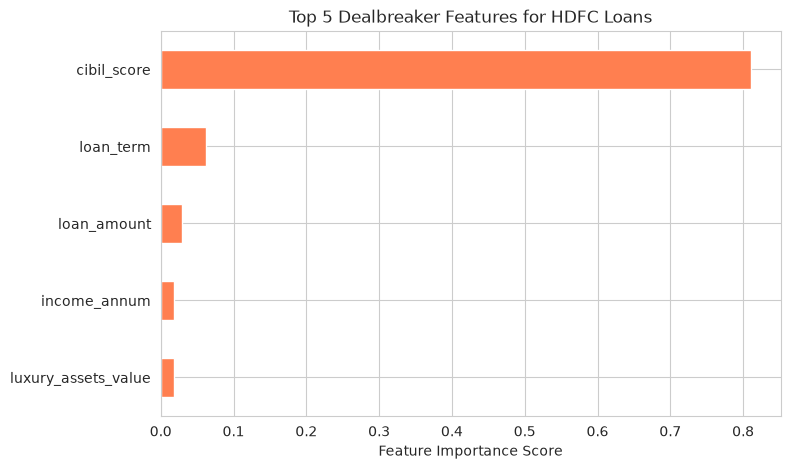

In [35]:
importances = pd.Series(rf_tree_classifier.feature_importances_, index=model_features.columns)
top_5 = importances.nlargest(5).sort_values(ascending=True)



plt.figure(figsize=(8, 5))
top_5.plot(kind='barh', color='coral')


plt.title("Top 5 Dealbreaker Features for HDFC Loans")
plt.xlabel("Feature Importance Score")
plt.show()

# should be the end ofr the coding part after this i lll justb write a third phase cell for like a summary and the useses 

Phase 3: Business Interpretation & Value


Business Impact for HDFC Stakeholders:


The Random Forest classifier drastically outperformed the baseline Logistic Regression, proving that loan approvals rely on complex, non-linear relationships rather than just a simple checklist. By deploying a model with this level of accuracy, HDFC Bank can automate the initial screening of thousands of loan applications per day. This reduces manual underwriter processing time, cuts operational costs, and gives customers much faster preliminary decisions. 



Key Drivers (What Actually Matters):
Looking at the feature importance chart, cibil_score is by far the biggest dealbreaker for loan applicants. No matter how much property an applicant owns or what their annual income is, a bad credit history immediately flags the application. 

For the bank's strategy, this means HDFC can safely implement a fast-track rejection system for applicants below a certain CIBIL threshold, reserving human employee hours only for edge-case applications that the AI flags as borderline.

In [ ]:
# Quick live test on a new sample applicant

# this is just a sample applicant to test the model and see if it works as expected 
# this is for live testing i can show 

sample_applicant = pd.DataFrame([{
    'no_of_dependents': 2,
    'education': 1,                # 1 = Graduate, 0 = Not Graduate
    'self_employed': 0,            # 1 = Yes, 0 = No
    'income_annum': 6500,
    'loan_amount': 1500000000,
    'loan_term': 12,
    'cibil_score': 500,
    'residential_assets_value': 8000000,
    'commercial_assets_value': 2000000,
    'luxury_assets_value': 5000000,
    'bank_asset_value': 3000000
}])




sample_scaled = scaler.transform(sample_applicant)
result = rf_tree_classifier.predict(sample_scaled)[0]
prob = rf_tree_classifier.predict_proba(sample_scaled)[0][1]



print("Decision:", "Approved" if result == 1 else "Rejected")
print(f"Approval Confidence: {prob * 100:.1f}%")



Decision: Rejected
Approval Confidence: 11.0%
